# 02 - Preprocessing and model training

This notebook shows, step by step, how the five classifiers are built, trained and
evaluated. It produces the same models and numbers as `train.py` (which is the script that
writes the files in `model/`); the notebook exists so that each model's code and results
can be read in one place.

Plan:

1. Load the official train and test splits.
2. Preprocessing: feature scaling (fitted on the training data only).
3. Train and evaluate five models, one section each.
4. Compare them.

Following the dataset documentation, there is **no cross-validation and no hyper-parameter
search**: each model is trained once on the training file and evaluated once on the test file.

## 1. Setup and data

In [1]:
import sys
import warnings
sys.path.insert(0, "..")  # lets the notebook import from src/

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from src.data_loader import CLASS_NAMES, load_test, load_train
from src.metrics import METRIC_NAMES, evaluate
from src.models import model_path
from src.preprocessing import SCALER_PATH, make_scaler, split_features_target

# scikit-learn 1.9 announces that SVC(probability=True) will be replaced in a future
# release. It is still the supported way to get probabilities for AUC, so the notice is hidden.
warnings.filterwarnings("ignore", message="The `probability` parameter")
sns.set_theme(style="whitegrid")
SEED = 42

In [2]:
X_train, y_train = split_features_target(load_train())
X_test, y_test = split_features_target(load_test())

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Classes:", sorted(y_train.unique()))

Training set: (4435, 36) | Test set: (2000, 36)
Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7)]


## 2. Preprocessing

The only preprocessing step is **standard scaling**: every feature is shifted to mean 0 and
scaled to standard deviation 1. The scaler learns the means and standard deviations from the
**training data only**, and the same values are then applied to the test data. Fitting it on
the test set would leak information about the test set into training.

No new features are created. The EDA notebook showed there are no missing values or
duplicate rows, and all 36 features are already numeric and on the same 0-255 scale.
Scaling still matters for KNN, SVM and Logistic Regression, which are sensitive to feature
scale. The Decision Tree and Naive Bayes are not, but they use the same pipeline so that all
five models are treated identically.

In [3]:
scaler = make_scaler().fit(X_train)          # learns mean and std from the training data only

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

summary = pd.DataFrame({
    "train mean (raw)": X_train.mean().head(4).round(1),
    "train std (raw)": X_train.std().head(4).round(1),
    "train mean (scaled)": X_train_scaled[:, :4].mean(axis=0).round(3),
    "train std (scaled)": X_train_scaled[:, :4].std(axis=0).round(3),
    "test mean (scaled)": X_test_scaled[:, :4].mean(axis=0).round(3),
})
summary

,train mean (raw),train std (raw),train mean (scaled),train std (scaled),test mean (scaled)
top_left_band1,69.5,13.6,0.0,1.0,-0.017
top_left_band2,83.9,22.7,0.0,1.0,-0.037
top_left_band3,99.3,16.7,-0.0,1.0,-0.006
top_left_band4,82.6,18.7,-0.0,1.0,0.006


After scaling, the training features have mean 0 and standard deviation 1. The test features
are close to, but not exactly, 0 and 1, which is expected because they were scaled with the
*training* statistics.

The same scaler is saved as a standalone preprocessing artifact (`model/scaler.joblib`, written
by `train.py`). Check that it matches the scaler fitted above:

In [4]:
saved_scaler = joblib.load(SCALER_PATH)
print("Saved scaler matches:", np.allclose(saved_scaler.mean_, scaler.mean_)
      and np.allclose(saved_scaler.scale_, scaler.scale_))

Saved scaler matches: True


## 3. Training and evaluation

`run_model` fits a pipeline (scaler followed by the classifier) on the training data,
predicts on the test data, and reports the six metrics, the confusion matrix and the
per-class report. It also checks that the predictions are identical to those of the saved
model in `model/`, which is the file the Streamlit app loads.

Precision, Recall and F1 are macro-averaged and AUC is one-vs-rest macro-averaged
(see `src/metrics.py`).

In [5]:
results = {}
LABELS = [f"{k} {v}" for k, v in CLASS_NAMES.items()]


def run_model(name, pipeline):
    pipeline.fit(X_train, y_train)                    # train once on the training split
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)
    classes = pipeline.classes_

    scores = evaluate(y_test, y_pred, y_proba, classes)
    results[name] = scores
    print(pd.Series(scores).round(4).to_string(), "\n")

    fig, ax = plt.subplots(figsize=(6.5, 5))
    sns.heatmap(confusion_matrix(y_test, y_pred, labels=classes), annot=True, fmt="d",
                cmap="YlGnBu", cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(f"{name}: confusion matrix (rows = actual, columns = predicted)", fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

    print(classification_report(y_test, y_pred, target_names=LABELS, zero_division=0))

    saved = joblib.load(model_path(name))
    print("Predictions identical to the saved model:", np.array_equal(saved.predict(X_test), y_pred))

### 3.1 Logistic Regression

A linear model that gives each class a score from a weighted sum of the features and turns the
scores into probabilities. `max_iter=1000` gives the solver enough iterations to converge on
the 36 scaled features; everything else is left at the scikit-learn default.

Accuracy     0.8395
AUC          0.9755
Precision    0.8116
Recall       0.7938
F1           0.7971
MCC          0.8032 



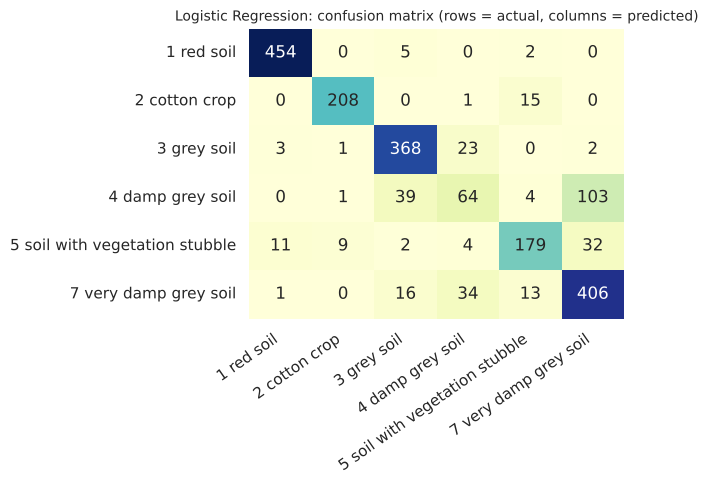

                                precision    recall  f1-score   support

                    1 red soil       0.97      0.98      0.98       461
                 2 cotton crop       0.95      0.93      0.94       224
                   3 grey soil       0.86      0.93      0.89       397
              4 damp grey soil       0.51      0.30      0.38       211
5 soil with vegetation stubble       0.84      0.76      0.80       237
         7 very damp grey soil       0.75      0.86      0.80       470

                      accuracy                           0.84      2000
                     macro avg       0.81      0.79      0.80      2000
                  weighted avg       0.83      0.84      0.83      2000

Predictions identical to the saved model: True


In [6]:
logistic_regression = Pipeline([
    ("scaler", make_scaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])
run_model("Logistic Regression", logistic_regression)

### 3.2 Decision Tree

Learns a sequence of yes/no questions about single features ("is `centre_band2` below 0.3?")
that split the data into purer and purer groups. With default settings it keeps splitting until
every leaf is pure, so it can fit the training data perfectly. The training accuracy printed
below shows how much it overfits.

Accuracy     0.8505
AUC          0.9002
Precision    0.8331
Recall       0.8306
F1           0.8317
MCC          0.8164 



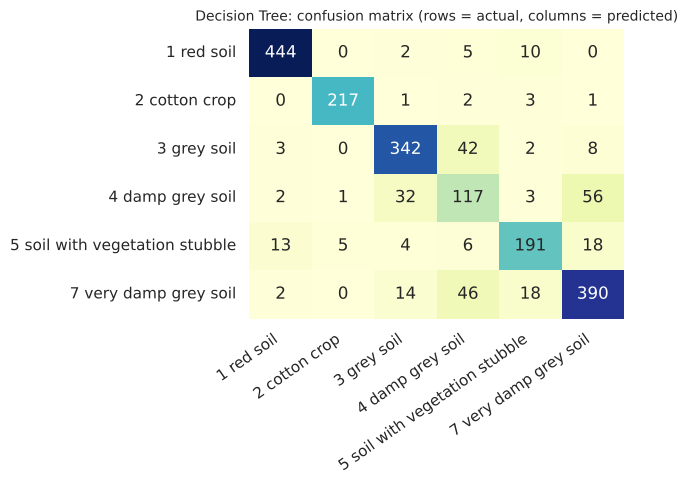

                                precision    recall  f1-score   support

                    1 red soil       0.96      0.96      0.96       461
                 2 cotton crop       0.97      0.97      0.97       224
                   3 grey soil       0.87      0.86      0.86       397
              4 damp grey soil       0.54      0.55      0.55       211
5 soil with vegetation stubble       0.84      0.81      0.82       237
         7 very damp grey soil       0.82      0.83      0.83       470

                      accuracy                           0.85      2000
                     macro avg       0.83      0.83      0.83      2000
                  weighted avg       0.85      0.85      0.85      2000

Predictions identical to the saved model: True

Tree depth: 21 | leaves: 382
Training accuracy: 1.0


In [7]:
decision_tree = Pipeline([
    ("scaler", make_scaler()),
    ("classifier", DecisionTreeClassifier(random_state=SEED)),
])
run_model("Decision Tree", decision_tree)

tree = decision_tree.named_steps["classifier"]
print("\nTree depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())
print("Training accuracy:", round(decision_tree.score(X_train, y_train), 4))

### 3.3 K-Nearest Neighbours

Classifies a pixel neighbourhood by looking at the 5 most similar training examples (smallest
distance in the 36-dimensional scaled feature space) and taking a majority vote. Because it is
distance based, the scaling step matters a lot here. `n_neighbors=5` is the usual starting
value and was not tuned.

Accuracy     0.9045
AUC          0.9786
Precision    0.8951
Recall       0.8886
F1           0.8916
MCC          0.8827 



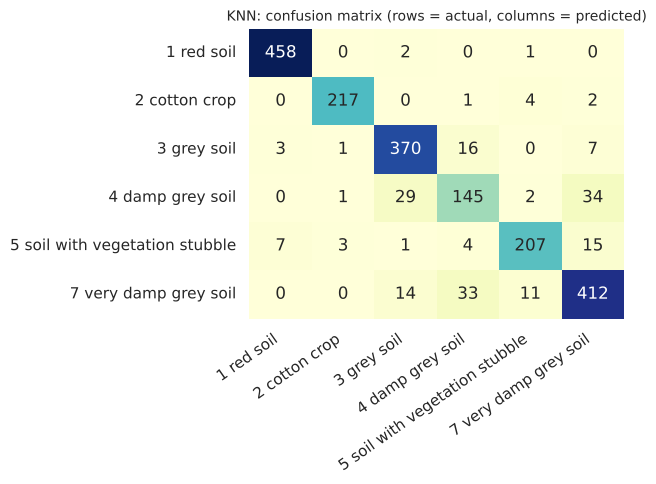

                                precision    recall  f1-score   support

                    1 red soil       0.98      0.99      0.99       461
                 2 cotton crop       0.98      0.97      0.97       224
                   3 grey soil       0.89      0.93      0.91       397
              4 damp grey soil       0.73      0.69      0.71       211
5 soil with vegetation stubble       0.92      0.87      0.90       237
         7 very damp grey soil       0.88      0.88      0.88       470

                      accuracy                           0.90      2000
                     macro avg       0.90      0.89      0.89      2000
                  weighted avg       0.90      0.90      0.90      2000

Predictions identical to the saved model: True


In [8]:
knn = Pipeline([
    ("scaler", make_scaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5)),
])
run_model("KNN", knn)

### 3.4 Naive Bayes (Gaussian)

Uses Bayes' rule: for each class it models every feature as a normal distribution, then
multiplies the per-feature likelihoods together, assuming the features are independent. The
features here are continuous pixel intensities, so the Gaussian variant is the right one.
The independence assumption is the weak point on this dataset, because neighbouring pixels are
strongly correlated (see the EDA notebook).

Accuracy     0.7965
AUC          0.9551
Precision    0.7864
Recall       0.7877
F1           0.7833
MCC          0.7531 



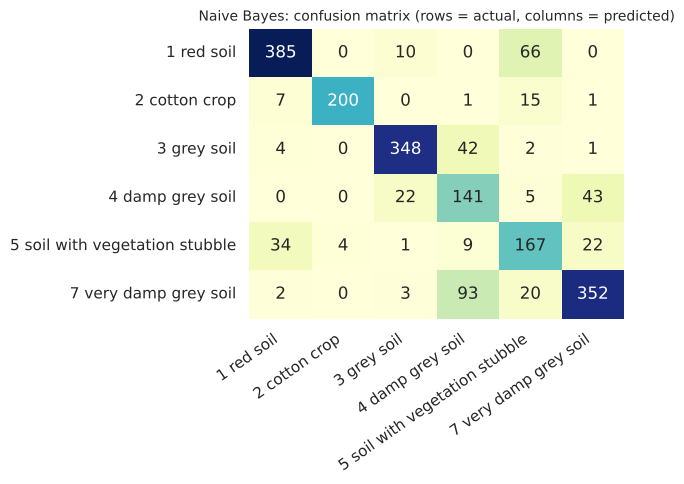

                                precision    recall  f1-score   support

                    1 red soil       0.89      0.84      0.86       461
                 2 cotton crop       0.98      0.89      0.93       224
                   3 grey soil       0.91      0.88      0.89       397
              4 damp grey soil       0.49      0.67      0.57       211
5 soil with vegetation stubble       0.61      0.70      0.65       237
         7 very damp grey soil       0.84      0.75      0.79       470

                      accuracy                           0.80      2000
                     macro avg       0.79      0.79      0.78      2000
                  weighted avg       0.82      0.80      0.80      2000

Predictions identical to the saved model: True


In [9]:
naive_bayes = Pipeline([
    ("scaler", make_scaler()),
    ("classifier", GaussianNB()),
])
run_model("Naive Bayes", naive_bayes)

### 3.5 Support Vector Machine

Finds the boundary that separates the classes with the widest possible margin. The RBF kernel
lets the boundary be curved, which allows it to separate classes that are not linearly
separable. `C` and `gamma` are left at their defaults. `probability=True` makes it also output
class probabilities, which are needed to calculate AUC.

Accuracy     0.8955
AUC          0.9850
Precision    0.8852
Recall       0.8724
F1           0.8769
MCC          0.8718 



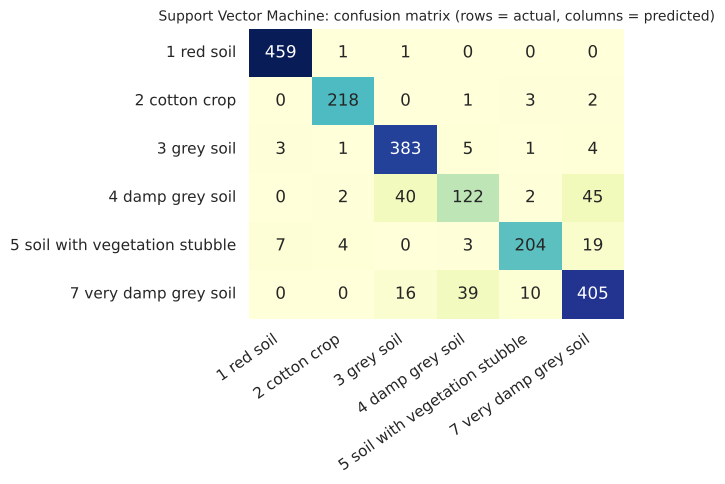

                                precision    recall  f1-score   support

                    1 red soil       0.98      1.00      0.99       461
                 2 cotton crop       0.96      0.97      0.97       224
                   3 grey soil       0.87      0.96      0.92       397
              4 damp grey soil       0.72      0.58      0.64       211
5 soil with vegetation stubble       0.93      0.86      0.89       237
         7 very damp grey soil       0.85      0.86      0.86       470

                      accuracy                           0.90      2000
                     macro avg       0.89      0.87      0.88      2000
                  weighted avg       0.89      0.90      0.89      2000



Predictions identical to the saved model: True


In [10]:
svm = Pipeline([
    ("scaler", make_scaler()),
    ("classifier", SVC(kernel="rbf", probability=True, random_state=SEED)),
])
run_model("Support Vector Machine", svm)

## 4. Comparison

In [11]:
comparison = pd.DataFrame(results).T[METRIC_NAMES]
comparison.index.name = "ML Model Name"
comparison.round(4).style.highlight_max(axis=0, color="#cfe8cf")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.839500,0.975500,0.811600,0.793800,0.797100,0.803200
Decision Tree,0.850500,0.900200,0.833100,0.830600,0.831700,0.816400
KNN,0.904500,0.978600,0.895100,0.888600,0.891600,0.882700
Naive Bayes,0.796500,0.955100,0.786400,0.787700,0.783300,0.753100
Support Vector Machine,0.895500,0.985000,0.885200,0.872400,0.876900,0.871800


In [12]:
# The notebook should reproduce the numbers written by train.py
from_script = pd.read_csv("../results/metrics_comparison.csv").set_index("ML Model Name")
print("Matches results/metrics_comparison.csv:",
      np.allclose(comparison.loc[from_script.index].values, from_script[METRIC_NAMES].values))

Matches results/metrics_comparison.csv: True


The README contains the same table together with a written observation for each model.